# Import Libraries and Load Dataset

In this step, we import the required Python libraries and load the dataset.

- Pandas: Used for data manipulation and analysis.
- NumPy: Used for numerical operations.
- Matplotlib and Seaborn: Used for data visualization.

We then display the first few rows and check the dataset dimensions.

In [14]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
df = pd.read_csv("vehicles.csv")

print("Dataset shape:", df.shape)
(df.head())

Dataset shape: (426880, 26)


,id,url,region,region_url,price,year,manufacturer,model,condition,cylinders,...,size,type,paint_color,image_url,description,county,state,lat,long,posting_date
0,7222695916,https://prescott.craigslist.org/cto/d/prescott...,prescott,https://prescott.craigslist.org,6000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,az,NaN,NaN,NaN
1,7218891961,https://fayar.craigslist.org/ctd/d/bentonville...,fayetteville,https://fayar.craigslist.org,11900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ar,NaN,NaN,NaN
2,7221797935,https://keys.craigslist.org/cto/d/summerland-k...,florida keys,https://keys.craigslist.org,21000,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,fl,NaN,NaN,NaN
3,7222270760,https://worcester.craigslist.org/cto/d/west-br...,worcester / central MA,https://worcester.craigslist.org,1500,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,ma,NaN,NaN,NaN
4,7210384030,https://greensboro.craigslist.org/cto/d/trinit...,greensboro,https://greensboro.craigslist.org,4900,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,nc,NaN,NaN,NaN


# Identify and Remove Duplicates

Duplicate rows are repeated records in the dataset. They may affect the analysis by giving repeated observations more weight.

In this step, we count the duplicate rows, remove them, and check the result.

In [15]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


In [16]:
df = df.drop_duplicates()

print("Shape after removing duplicates:", df.shape)
print("Remaining duplicate rows:", df.duplicated().sum())

Shape after removing duplicates: (426880, 26)
Remaining duplicate rows: 0


# Handle Inconsistent Text

Text values may contain extra spaces or inconsistent capitalization, such as ""FORD"" and ""Ford"".

We standardize text by removing leading and trailing spaces and converting letters to lowercase. This helps make text values more consistent.

In [17]:
text_cols = df.select_dtypes(
    include=["object", "string"]
).columns

for col in text_cols:
    df[col] = (
        df[col]
        .astype("string")
        .str.strip()
        .str.lower()
    )

print("Text standardization completed.")

Text standardization completed.


# Detect and Handle Invalid Values

Invalid values are values that do not make sense for the feature being measured.

For the used car dataset, examples include:

- Negative prices.
- Manufacturing years outside a reasonable range.
- Negative odometer readings.

We convert the numerical columns to numeric data types, inspect invalid values, and remove records with clearly invalid values. Missing values are handled separately.

In [18]:
for col in ["price", "year", "odometer"]:
    df[col] = pd.to_numeric(df[col], errors="coerce")

print("Negative prices:", (df["price"] < 0).sum())
print("Zero prices:", (df["price"] == 0).sum())

print(
    "Invalid years:",
    (~df["year"].between(1900, 2027) & df["year"].notna()).sum()
)

print("Negative odometer:", (df["odometer"] < 0).sum())

Negative prices: 0
Zero prices: 32895
Invalid years: 0
Negative odometer: 0


In [19]:
# Remove zero or negative prices
df = df[df["price"] > 0]

# Keep missing years for the missing-values step
df = df[
    df["year"].isna()
    | df["year"].between(1900, 2027)
]

# Remove negative odometer readings
df = df[
    df["odometer"].isna()
    | (df["odometer"] >= 0)
]

print("Shape after handling invalid values:", df.shape)

Shape after handling invalid values: (393985, 26)


# Identify Missing Values

Missing values occur when information is unavailable for some records.
We calculate the number and percentage of missing values in each column. This helps us decide whether to remove a column or fill its missing values using a suitable method.

In [20]:
na = df.isna ().sum ()
percentage = (na / len(df) * 100).round (2)

missing = pd.DataFrame({
    "missing": na,
    "percentage": percentage
})

missing = missing [missing["missing"] > 0]
missing = missing.sort_values("missing", ascending=False)

missing

,missing,percentage
county,393985,100.00
size,282933,71.81
cylinders,160410,40.71
VIN,152158,38.62
condition,151389,38.43
drive,120254,30.52
paint_color,117149,29.73
type,85932,21.81
manufacturer,16185,4.11
title_status,7734,1.96


In [21]:
print(df["size"].value_counts(dropna=False))

size
<NA>           282933
full-size       58509
mid-size        31925
compact         17733
sub-compact      2885
Name: count, dtype: Int64


In [22]:
df = df.drop(columns=["size"])

print("Shape after dropping size:", df.shape)

Shape after dropping size: (393985, 25)


In [23]:
na = df.isna().sum()
percentage = (na / len(df) * 100).round(2)

missing = pd.DataFrame({
    "missing": na,
    "percentage": percentage
})

missing = missing[missing["missing"] > 0]
missing = missing.sort_values("missing", ascending=False)

missing

,missing,percentage
county,393985,100.00
cylinders,160410,40.71
VIN,152158,38.62
condition,151389,38.43
drive,120254,30.52
paint_color,117149,29.73
type,85932,21.81
manufacturer,16185,4.11
title_status,7734,1.96
model,4701,1.19


# Remove Unnecessary Columns

Some columns are identifiers, links, or descriptive fields that we will not use in this preprocessing analysis.
The "size" column also contains a high percentage of missing values. We remove the selected columns to simplify the dataset.
This decision is based on the current project scope and may be revised if any of these columns are required later.

In [24]:
columns_to_drop = [
    "id", "url", "region_url", "VIN",
    "image_url", "description", "county",
    "lat", "long", "size"
]

df = df.drop(
    columns=columns_to_drop,
    errors="ignore"
)

print("Shape after dropping columns:", df.shape)

Shape after dropping columns: (393985, 16)


# Handle Missing Values

After examining the missing-value report, we handle the remaining missing values.

- We remove rows where the target variable "price" is missing.
- We use the median to fill missing values in "year" and "odometer".
- We use ""Unknown"" for missing categorical values.

The median is less sensitive to extreme values than the mean. The ""Unknown"" label preserves records without inventing a category.

In [25]:
# Remove rows with missing target values
df = df.dropna(subset=["price"])

# Fill missing numerical values
for col in ["year", "odometer"]:
    df[col] = df[col].fillna(df[col].median())

# Fill missing categorical values
text_cols = df.select_dtypes(
    include=["object", "string", "category"]
).columns

for col in text_cols:
    df[col] = df[col].fillna("Unknown")

print("Remaining missing values:", df.isnull().sum().sum())

Remaining missing values: 0


# Detect Outliers Using Boxplots

Outliers are observations that are unusually far from the rest of the data.
We use boxplots to visualize possible outliers in "price", "year", and "odometer".
An outlier is not necessarily an error. For example, a luxury car may legitimately have a very high price. Therefore, we inspect outliers before deciding whether to remove or modify them.

In [28]:
# Select numeric columns for outlier detection
numeric_cols = df.select_dtypes(include=["number"]).columns.tolist()

print("Numeric columns:", numeric_cols)

Numeric columns: ['price', 'year', 'odometer']


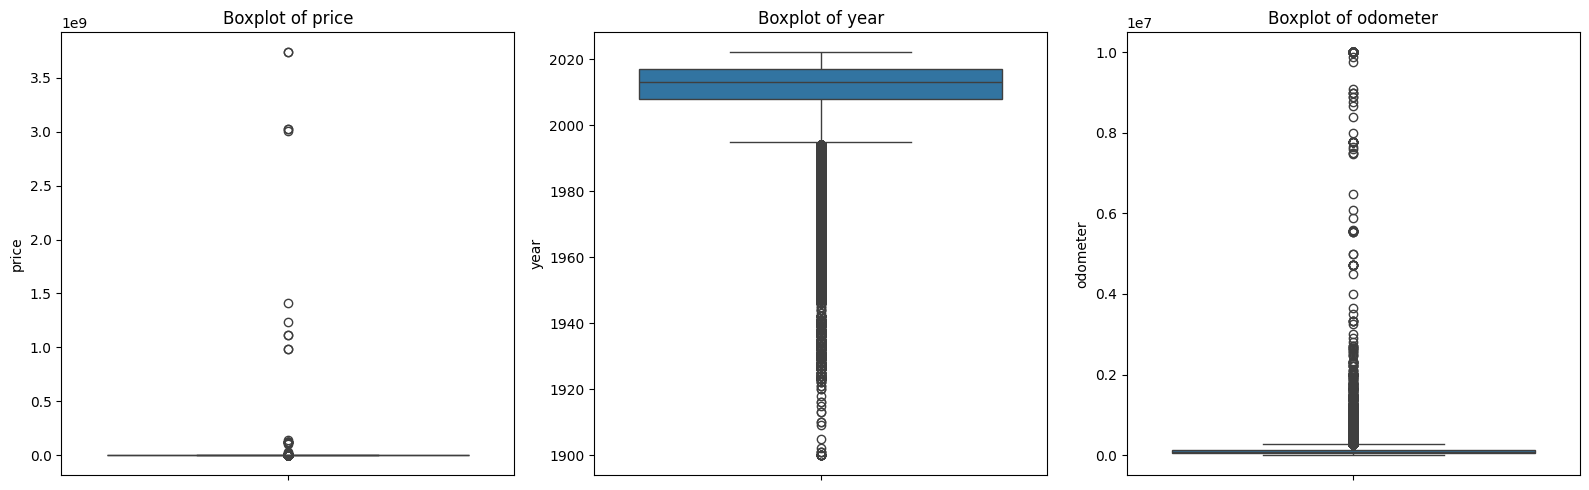

In [33]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

for col, ax in zip(numeric_cols, axes):
    sns.boxplot(y=df[col], ax=ax)
    ax.set_title(f"Boxplot of {col}")

plt.tight_layout()
plt.show()

# Calculate Outliers Using the IQR Method

The Interquartile Range (IQR) measures the spread of the middle 50% of the data.

- "Q1": First quartile (25th percentile).
- "Q3": Third quartile (75th percentile).
- "IQR = Q3 - Q1".

We calculate the lower and upper bounds. Values outside these bounds are flagged as potential outliers.

Lower Bound = Q1 − 1.5 × IQR

Upper Bound = Q3 + 1.5 × IQR

In this step, we identify and count potential outliers without automatically deleting them.

In [29]:
for col in numeric_cols:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print("Q1:", Q1)
    print("Q3:", Q3)
    print("IQR:", IQR)
    print("Lower Bound:", lower_bound)
    print("Upper Bound:", upper_bound)
    print("Number of Outliers:", len(outliers))


Column: price
Q1: 7000.0
Q3: 27590.0
IQR: 20590.0
Lower Bound: -23885.0
Upper Bound: 58475.0
Number of Outliers: 7779

Column: year
Q1: 2008.0
Q3: 2017.0
IQR: 9.0
Lower Bound: 1994.5
Upper Bound: 2030.5
Number of Outliers: 15593

Column: odometer
Q1: 38253.0
Q3: 135000.0
IQR: 96747.0
Lower Bound: -106867.5
Upper Bound: 280120.5
Number of Outliers: 3925


# Final Data Quality Check

In the final step, we review the dataset after preprocessing.
We check its dimensions, remaining missing values, and duplicate rows. We also display summary statistics to confirm that the data is ready for the next stage of the project.

In [31]:
print("Final dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

display(df.head())
display(df.describe(include="all").T)

Final dataset shape: (393985, 16)
Duplicate rows: 33
Total missing values: 0


,region,price,year,manufacturer,model,condition,cylinders,fuel,odometer,title_status,transmission,drive,type,paint_color,state,posting_date
0,prescott,6000,2013.0,Unknown,Unknown,Unknown,Unknown,Unknown,87000.0,Unknown,Unknown,Unknown,Unknown,Unknown,az,Unknown
1,fayetteville,11900,2013.0,Unknown,Unknown,Unknown,Unknown,Unknown,87000.0,Unknown,Unknown,Unknown,Unknown,Unknown,ar,Unknown
2,florida keys,21000,2013.0,Unknown,Unknown,Unknown,Unknown,Unknown,87000.0,Unknown,Unknown,Unknown,Unknown,Unknown,fl,Unknown
3,worcester / central ma,1500,2013.0,Unknown,Unknown,Unknown,Unknown,Unknown,87000.0,Unknown,Unknown,Unknown,Unknown,Unknown,ma,Unknown
4,greensboro,4900,2013.0,Unknown,Unknown,Unknown,Unknown,Unknown,87000.0,Unknown,Unknown,Unknown,Unknown,Unknown,nc,Unknown


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
region,393985,404,columbus,3392,NaN,NaN,NaN,NaN,NaN,NaN,NaN
price,393985.0,NaN,NaN,NaN,81477.628049,12680636.885187,1.0,7000.0,15000.0,27590.0,3736928711.0
year,393985.0,NaN,NaN,NaN,2011.012051,9.617171,1900.0,2008.0,2013.0,2017.0,2022.0
manufacturer,393985,43,ford,64855,NaN,NaN,NaN,NaN,NaN,NaN,NaN
model,393985,27229,f-150,7178,NaN,NaN,NaN,NaN,NaN,NaN,NaN
condition,393985,7,Unknown,151389,NaN,NaN,NaN,NaN,NaN,NaN,NaN
cylinders,393985,9,Unknown,160410,NaN,NaN,NaN,NaN,NaN,NaN,NaN
fuel,393985,6,gas,330431,NaN,NaN,NaN,NaN,NaN,NaN,NaN
odometer,393985.0,NaN,NaN,NaN,98661.334553,205318.415334,0.0,38253.0,87000.0,135000.0,10000000.0
title_status,393985,7,clean,372867,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [32]:
# Remove duplicate rows
df = df.drop_duplicates().copy()

# Final validation
print("Final dataset shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Total missing values:", df.isnull().sum().sum())

Final dataset shape: (393952, 16)
Duplicate rows: 0
Total missing values: 0
